In [10]:
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

Global min is (1,1)

In [11]:
def rosenbrock(x, y=None):
    if y is None:
        x, y = x[0], x[1]
    return (1 - x)**2 + 100 * (y - x**2)**2

In [12]:
def gradRosenbrock(x, y=None):
    if y is None:
        x, y = x[0], x[1]
    df_dx = -2*(1-x) - 400*x*(y-x**2) 
    df_dy =  200*(y-x**2)   

    return np.array([df_dx, df_dy])


The frist momente is $$ m_t = \beta_1  m_{t-1} + (1-\beta_1)g_t$$

The second moment is $$ v_t = \beta_2 v_{t-1} + (1-\beta_2)g_{t}²$$

Update paramters : $$\theta_t = \theta_{t-1} - \frac{\eta}{\sqrt{\hat{v}} + \epsilon} \hat{m_t}$$

Since the corretion of bias: $$\hat{m_t} = \frac{m_t}{1 - \beta_{1}^t}$$  $$\hat{v_t} = \frac{v_t}{1 - \beta_{2}^t}$$



In [13]:
def adamOptimizer(start, eta,epoch, beta_1, beta_2, fun, gradfun, epsilon, tolerance):
    x,y = float(start[0]), float(start[1])
    
    # Initial values
    path = [(x,y)]
    loss = [fun(x,y)]
    
    # Initial moments
    m = np.array([0.0,0.0])
    v = np.array([0.0,0.0])

    for t in range (1, epoch+1): # Remember v_0 just used
        grad = gradfun(x, y)

        if np.linalg.norm(grad) < tolerance:
            break

        #moments
        m =  m * beta_1 + (1 - beta_1)*grad
        v =  v*  beta_2 + (1 - beta_2)*(grad**2)

        # bias

        m_hat = m/(1-beta_1**t)
        v_hat = v/(1-beta_2**t)

        # update

        x = x - (eta * m_hat[0])/(epsilon+np.sqrt(v_hat[0]))
        y = y - (eta * m_hat[1])/(epsilon+np.sqrt(v_hat[1]))

        path.append((x,y))
        loss.append(fun(x,y))

    return path, loss
    

In [16]:
# config
epoch  = 200
tolerance = 1e-12
# hiperparametrs
eta = 0.02
bta_1 = 0.9
bta_2 = 0.999
epsilon = 1e-8



path, loss = adamOptimizer(
    np.array([-1.2, 1.0]),
    eta,
    epoch,
    bta_1,
    bta_2,
    rosenbrock,
    gradRosenbrock,
    epsilon,
    tolerance
)

In [19]:
path = np.array(path)

x_vals = np.linspace(-12.0, 12.0, 400)
y_vals = np.linspace(-6.0, 6.0, 400)

# criar a matriz
X,Y = np.meshgrid(x_vals, y_vals)
Z = rosenbrock(X,Y)

<a list of 9 text.Text objects>

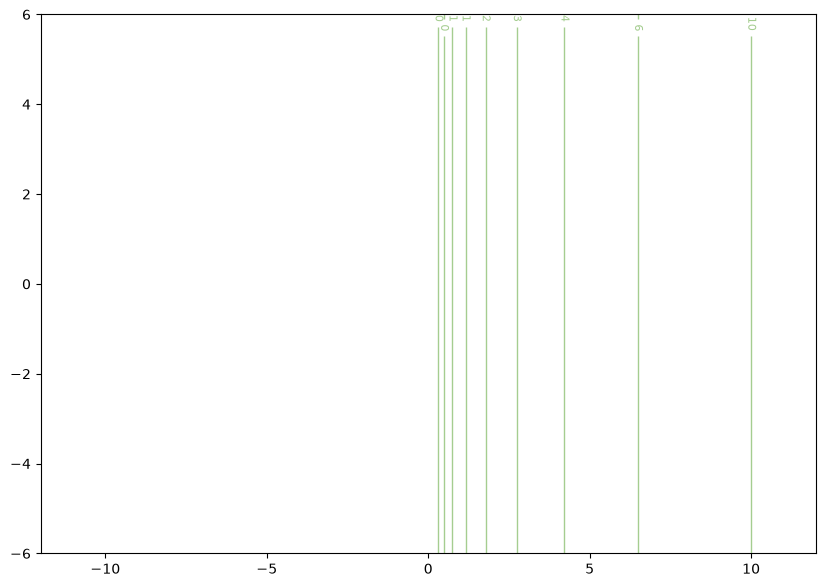

In [ ]:
# PLOT
plt.figure(figsize=(10,7))

level = np.logspace(-0.5, 4, 25)

contours = plt.contour(X,Y,X, level, cmap="crest", linewidth=1.0)

plt.clabel(contours, inline=True, fontsize=8, fmt="%.0f")



plt.plot()



In [ ]:
for x in range(-6,6):
    y=np.linspace(-6,6, 400)
    rosenbrock(x,y)

sns.sacatterplot(

)